# Group component MD — synchrony of each trained pair, across subjects

The group version of `component_md.ipynb`. Reads the per-trial values that notebook writes
(`analysis/s<sn>_component_md.csv`, so run it for every subject first) and writes into
`figures/group/component_md/`:

| file | contents |
|---|---|
| `01_component_md.png` | learning curve, one panel per component slot, one point per block per chord |
| `01_component_md_pooled.png` | the same with Test 1 and Test 2 each collapsed to one point per chord |
| `02_tests_by_chord.png` | Test 1 → Test 2 → end of 4-finger practice, every subject shown |

**Component MD** is the MD of one trained pair's force path in its own 2-D space (thumb+index
or ring+pinky), from the pair leaving baseline to the pair reaching its held target; see
`component_md.ipynb`. Lower = the two fingers move more simultaneously. In a 4-finger chord
each slot either reproduces the trained component or is its flipped, untrained pattern; the
untrained slots are the control.

**How a group point is made** (as in `group_performance.ipynb`). Each subject is first
summarised as in their own figures, by the **median** component MD of their correct trials
for that chord, slot and block(s). The group point is the **mean of those per-subject
medians**, and the bar is **±1 SEM across subjects**.

**s100 is included for days 1–3 only** (3-day pilot, stops after block 38): blocks 1–38
average 5 subjects, the 4-finger training blocks 39–52 average 4. A point that rests on
fewer subjects than that (the chord was not presented in that block, or the subject had no
correct trial of it) is drawn **faded**. Hollow markers keep their meaning from the
single-subject figure: the slot is the flipped, untrained pattern.

The per-block subject values are saved to `analysis/group_component_md.csv` for stats.

## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

# project root = the folder that contains target/ and data/
ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils import timeline
from utils.chords import ChordRoles
from utils.design import (LAST_BLOCK, SEGMENTS, TEST1_BLOCKS, TEST2_BLOCKS, TRAIN_EARLY,
                          TRAIN_LATE, day_of_block)

SUBJECTS = [100, 101, 102, 103, 104]   # <<< s100 is the 3-day pilot: it only contributes to blocks 1-38

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ROOT / "figures" / "group" / "component_md"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})

cmd = pd.concat([pd.read_csv(ANALYSIS_DIR / f"s{sn}_component_md.csv") for sn in SUBJECTS],
                ignore_index=True)
COLLECTED = set(cmd.BN.unique())
SUBJ_TXT = ", ".join(f"s{sn}" for sn in SUBJECTS)
DESIGN = {sn: set(day_of_block(sn)) for sn in SUBJECTS}     # blocks each subject was meant to run


def n_expected(blocks):
    """How many subjects' designs include these blocks (s100 stops at block 38)."""
    return sum(set(blocks) <= DESIGN[sn] for sn in SUBJECTS)


N_TXT = " / ".join(dict.fromkeys(  # e.g. "5 / 4"
    f"{n_expected([b])}" for b in sorted(set().union(*DESIGN.values()))))
SHORT = {sn: LAST_BLOCK[sn] for sn in SUBJECTS if sn in LAST_BLOCK}
SHORT_TXT = "; ".join(f"s{sn} through block {b} only" for sn, b in SHORT.items())

print(cmd.groupby("sn").agg(rows=("cMD", "size"), last_block=("BN", "max"),
                            missing_cMD=("cMD", lambda v: v.isna().sum())).to_string())

     rows  last_block  missing_cMD
sn                                
100   842          38            0
101  1447          52            0
102   976          52            0
103  1269          52            0
104  1295          52            0


## Chord roles

Built per subject from the data (`utils/chords.py`), and checked to be the same for every
subject, since the figures key on chord ID.

In [2]:
roles_of = {sn: ChordRoles(trained=d.loc[d.kind == "2f", "chordID"].unique(),
                           tested=d.loc[d.kind == "4f", "chordID"].unique())
            for sn, d in cmd.groupby("sn")}
roles = roles_of[SUBJECTS[0]]
assert all(r.trained == roles.trained and r.tested == roles.tested for r in roles_of.values()), \
    "subjects differ in their chord set - group by role, not chord ID"

TESTED, TRAINED = roles.tested, roles.trained        # tested: both -> 1st -> 2nd -> neither
LABEL, COLOR, MARKER = roles.label, roles.color, roles.marker
SLOTS = roles.slots                                   # [(0, 1), (3, 4)]
for slot in SLOTS:
    inside = [c for c in TESTED if roles.contains(c, slot)]
    print(f"  {roles.slot_name(slot):<12} trained component {roles.component[slot]}; "
          f"trained slot in {inside}, flipped in {[c for c in TESTED if c not in inside]}")

  thumb+index  trained component 12999; trained slot in [12912, 12921], flipped in [21912, 21921]
  ring+pinky   trained component 99912; trained slot in [12912, 21912], flipped in [12921, 21921]


## Per-subject values and the group summary

`per_subject(blocks, chord, slot)` gives one median per subject; `group(vals, blocks)` the
mean, SEM, number of contributing subjects, and whether that is everyone the design allows.

In [3]:
def per_subject(blocks, chord, slot):
    """Median component MD per subject for `chord` at `slot` over `blocks` (index = sn)."""
    d = cmd[cmd.BN.isin(blocks) & (cmd.chordID == chord) & (cmd.slot == roles.slot_name(slot))]
    return d.dropna(subset=["cMD"]).groupby("sn").cMD.median()


def group(vals, blocks):
    """(mean, SEM, n, full) across subjects. `full` is False when fewer subjects contribute
    than the design allows for `blocks`; SEM is 0 when only one subject contributes."""
    n = len(vals)
    if n == 0:
        return np.nan, np.nan, 0, False
    sem = vals.std(ddof=1) / np.sqrt(n) if n > 1 else 0.0
    return vals.mean(), sem, n, n == n_expected(blocks)


rows = []
for b in sorted(COLLECTED):
    d_b = cmd[cmd.BN == b]
    for slot in SLOTS:
        for c in sorted(d_b.loc[d_b.slot == roles.slot_name(slot), "chordID"].unique()):
            for sn, v in per_subject([b], c, slot).items():
                rows.append(dict(sn=sn, BN=b, chordID=c, slot=roles.slot_name(slot),
                                 trained=roles.contains(c, slot) if c in TESTED else True,
                                 cMD=v))
table = pd.DataFrame(rows)
table.to_csv(ANALYSIS_DIR / "group_component_md.csv", index=False)
print(f"{len(table)} rows -> analysis/group_component_md.csv")

952 rows -> analysis/group_component_md.csv


## Learning curve

Same layout as the single-subject figure: one panel per component slot. In the training
blocks the line is the component on its own. In the 4-finger blocks each chord is drawn for
that slot: **filled marker, solid line** where the slot is the trained component, **hollow
marker, dashed line** where it is the flipped, untrained pattern. Faded = fewer subjects
than the design allows.

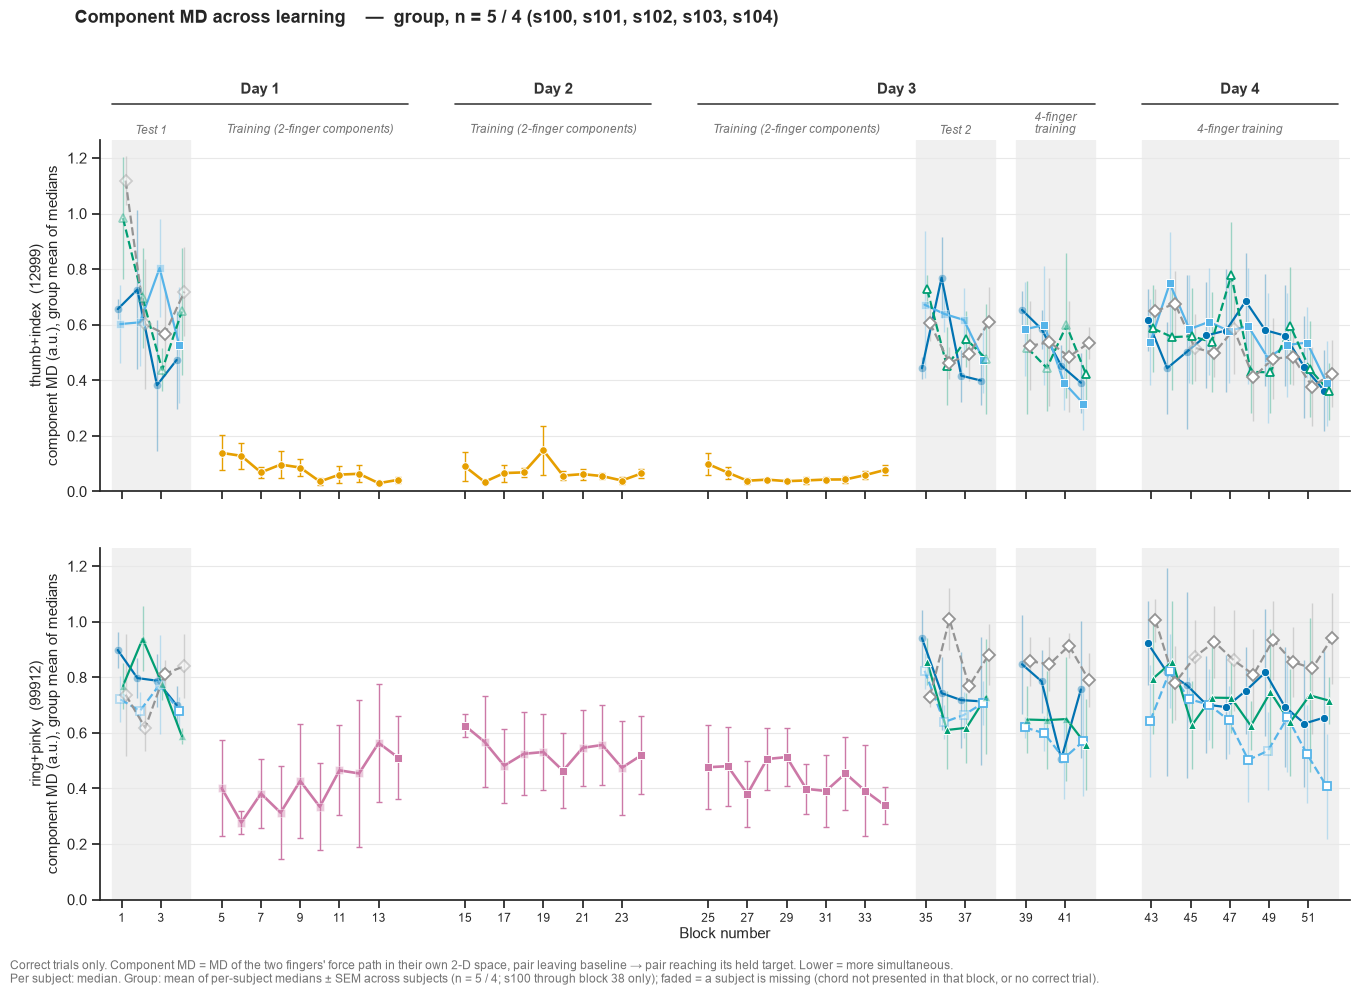

wrote figures/group/component_md/01_component_md.png


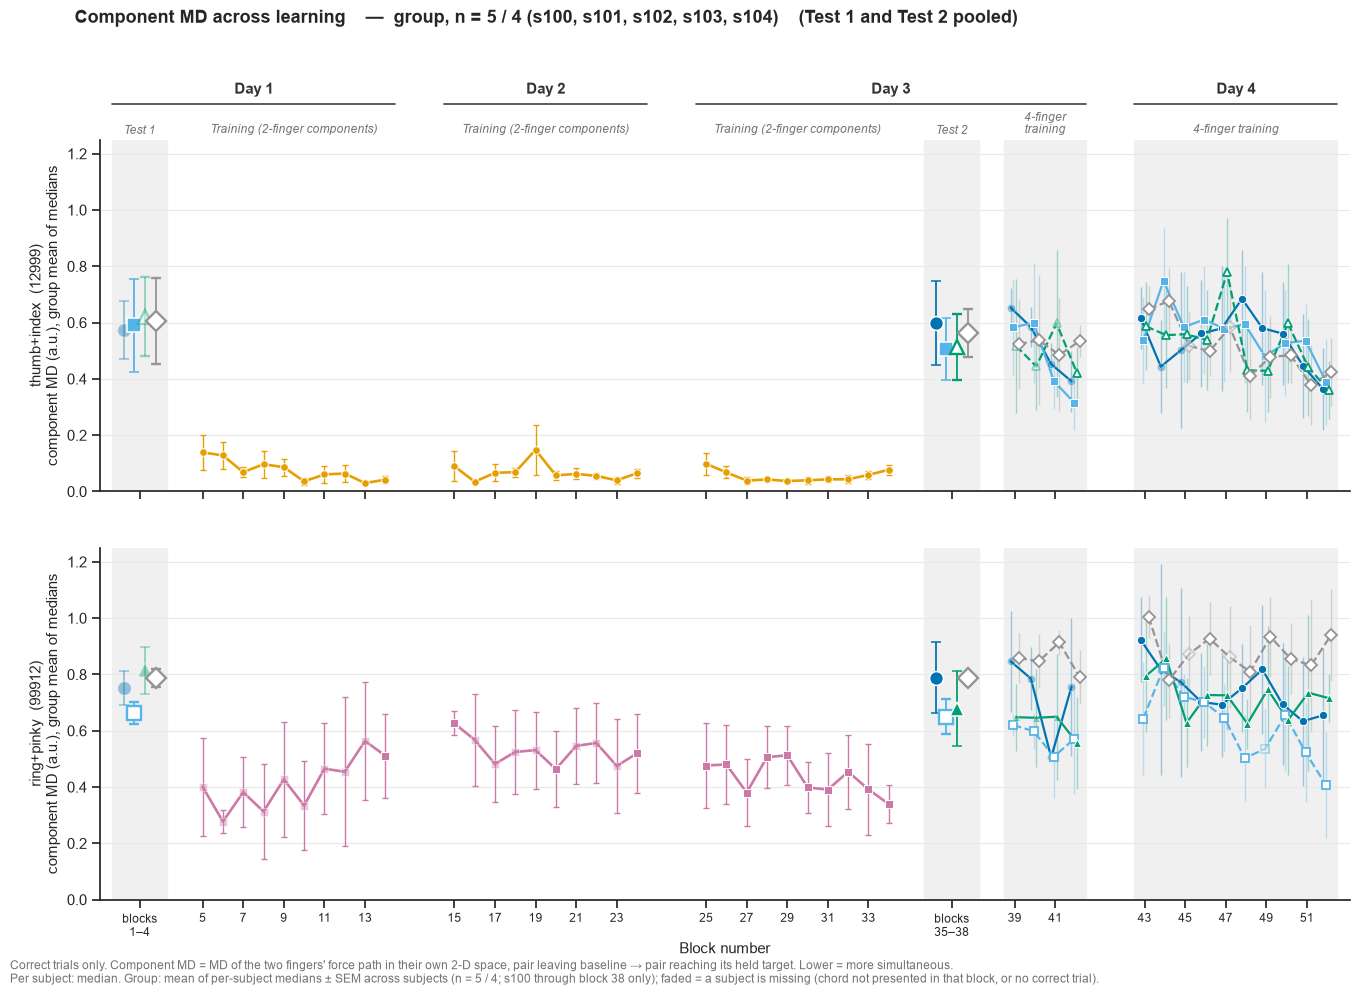

wrote figures/group/component_md/01_component_md_pooled.png


In [4]:
dodge = dict(zip(TESTED, np.linspace(-0.2, 0.2, len(TESTED))))
dodge_pooled = dict(zip(TESTED, np.linspace(-0.78, 0.78, len(TESTED))))
FADE = .4


def style(c, slot):
    """Filled + solid if `slot` of chord c is the trained component, else hollow + dashed."""
    if c not in TESTED or roles.contains(c, slot):
        return dict(color=COLOR[c], marker=MARKER[c], mfc=COLOR[c], mec="white", mew=.7, ls="-")
    return dict(color=COLOR[c], marker=MARKER[c], mfc="white", mec=COLOR[c], mew=1.3, ls="--")


for pool_tests in (False, True):
    segs = timeline.layout(pool_tests)
    fig, axes = plt.subplots(2, 1, figsize=(17, 10), sharex=True, sharey=True)

    for ax, slot in zip(axes, SLOTS):
        timeline.draw_background(ax, segs, COLLECTED)
        comp = roles.component[slot]

        for seg in segs:
            four = seg["kind"] == "4f"
            for c in (TESTED if four else [comp]):
                st = style(c, slot)
                if seg["pooled"]:
                    m, e, n, full = group(per_subject(seg["blocks"], c, slot), seg["blocks"])
                    if n:
                        ax.errorbar(seg["center"] + dodge_pooled[c], m, yerr=e, ms=10, lw=0,
                                    capsize=3.5, elinewidth=1.3, zorder=4,
                                    alpha=1 if full else FADE,
                                    **{**st, "mew": st["mew"] + .4})
                    continue
                pts = [(seg["x"][b] + (dodge[c] if four else 0),
                        *group(per_subject([b], c, slot), [b])) for b in seg["blocks"]]
                pts = [p for p in pts if p[3] > 0]
                if not pts:
                    continue
                xs, ys, es, ns, full = map(np.array, zip(*pts))
                eb = ax.errorbar(xs, ys, yerr=es, marker="none", color=st["color"], ls=st["ls"],
                                 lw=1.6 if four else 1.9, capsize=0 if four else 2.5,
                                 elinewidth=1, zorder=4 if four else 3)
                if four:
                    for coll in eb[2]:
                        coll.set_alpha(.35)
                mk = {k: st[k] for k in ("color", "marker", "mfc", "mec", "mew")}
                ms = 6 if four else 5.5
                ax.plot(xs[full], ys[full], ls="none", ms=ms, zorder=5, **mk)
                ax.plot(xs[~full], ys[~full], ls="none", ms=ms, zorder=5, alpha=FADE, **mk)

        ax.set_ylabel(f"{roles.slot_name(slot)}  ({comp})\ncomponent MD (a.u.), group mean of medians",
                      fontsize=11)
        ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)

    axes[0].set_ylim(bottom=0)
    timeline.draw_axis(axes[0], segs, headers=True)
    timeline.draw_axis(axes[1], segs, headers=False)
    axes[1].set_xlabel("Block number", fontsize=11, labelpad=2)
    axes[0].tick_params(labelbottom=False)

    h_test = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=7, lw=1.6,
                     mec="white", mew=.8, label=LABEL[c]) for c in TESTED]
    h_train = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=6, lw=1.9,
                      mec="white", mew=.7, label=LABEL[c]) for c in TRAINED]
    h_style = [Line2D([], [], color="0.35", marker="o", ms=7, lw=1.6, mec="white", mew=.8,
                      label="slot = the trained component"),
               Line2D([], [], color="0.35", marker="o", ms=7, lw=1.6, ls="--", mfc="white",
                      mec="0.35", mew=1.3, label="slot = flipped, untrained pattern"),
               Line2D([], [], color="0.35", marker="o", ms=7, lw=0, mec="white", mew=.8,
                      alpha=FADE, label="faded = fewer subjects\nthan the design allows")]
    for handles, title, y, ax in [
            (h_test, "4-finger chords" + ("  (tests pooled)" if pool_tests else "  (per block)"),
             1.0, axes[0]),
            (h_train, "2-finger components alone", .38, axes[0]),
            (h_style, "In a 4-finger chord, this slot is…", 1.0, axes[1])]:
        leg = ax.legend(handles=handles, title=title, loc="upper left",
                        bbox_to_anchor=(1.005, y), frameon=False, fontsize=9, labelspacing=.5)
        leg._legend_box.align = "left"; leg.get_title().set_fontweight("bold")
        ax.add_artist(leg)

    fig.text(.012, .012,
             "Correct trials only. Component MD = MD of the two fingers' force path in their own "
             "2-D space, pair leaving baseline → pair reaching its held target. Lower = more "
             "simultaneous.\nPer subject: median. Group: mean of per-subject medians ± SEM across "
             f"subjects (n = {N_TXT}" + (f"; {SHORT_TXT}" if SHORT else "") + "); faded = a subject "
             "is missing (chord not presented in that block, or no correct trial).",
             fontsize=8.5, color="0.45", ha="left")
    fig.suptitle(f"Component MD across learning    —  group, n = {N_TXT} ({SUBJ_TXT})"
                 + ("    (Test 1 and Test 2 pooled)" if pool_tests else ""),
                 fontsize=13, fontweight="bold", x=.05, y=.985, ha="left", color="0.15")
    sns.despine(fig=fig)
    fig.subplots_adjust(left=.065, right=.80, top=.855, bottom=.095, hspace=.16)
    fname = "01_component_md" + ("_pooled" if pool_tests else "") + ".png"
    fig.savefig(FIG_DIR / fname, dpi=200, facecolor="white")
    plt.show()
    print(f"wrote {(FIG_DIR / fname).relative_to(ROOT)}")

## Test 1 → Test 2 → end of 4-finger practice

The pre/post comparison per chord, with every subject visible. Rows are the two component
slots, columns the four tested chords (both → 1st → 2nd → neither component trained). In
each panel the title says whether that slot is the trained component or the flipped
pattern. Grey lines are single subjects; the coloured line is the group mean ± SEM.

The horizontal lines are the component produced on its own in training (group mean of
per-subject medians): dotted = first four training blocks, dashed = last four. They show how
synchronous the pair is alone, early and late in training, as a target for the chord.

The third point is the last four blocks of 4-finger practice on day 4. s100 stops at Test 2
(pilot), so its line has no third point. Any other missing point (open group marker with its
n) means that subject had no correct trial of that chord in that phase.

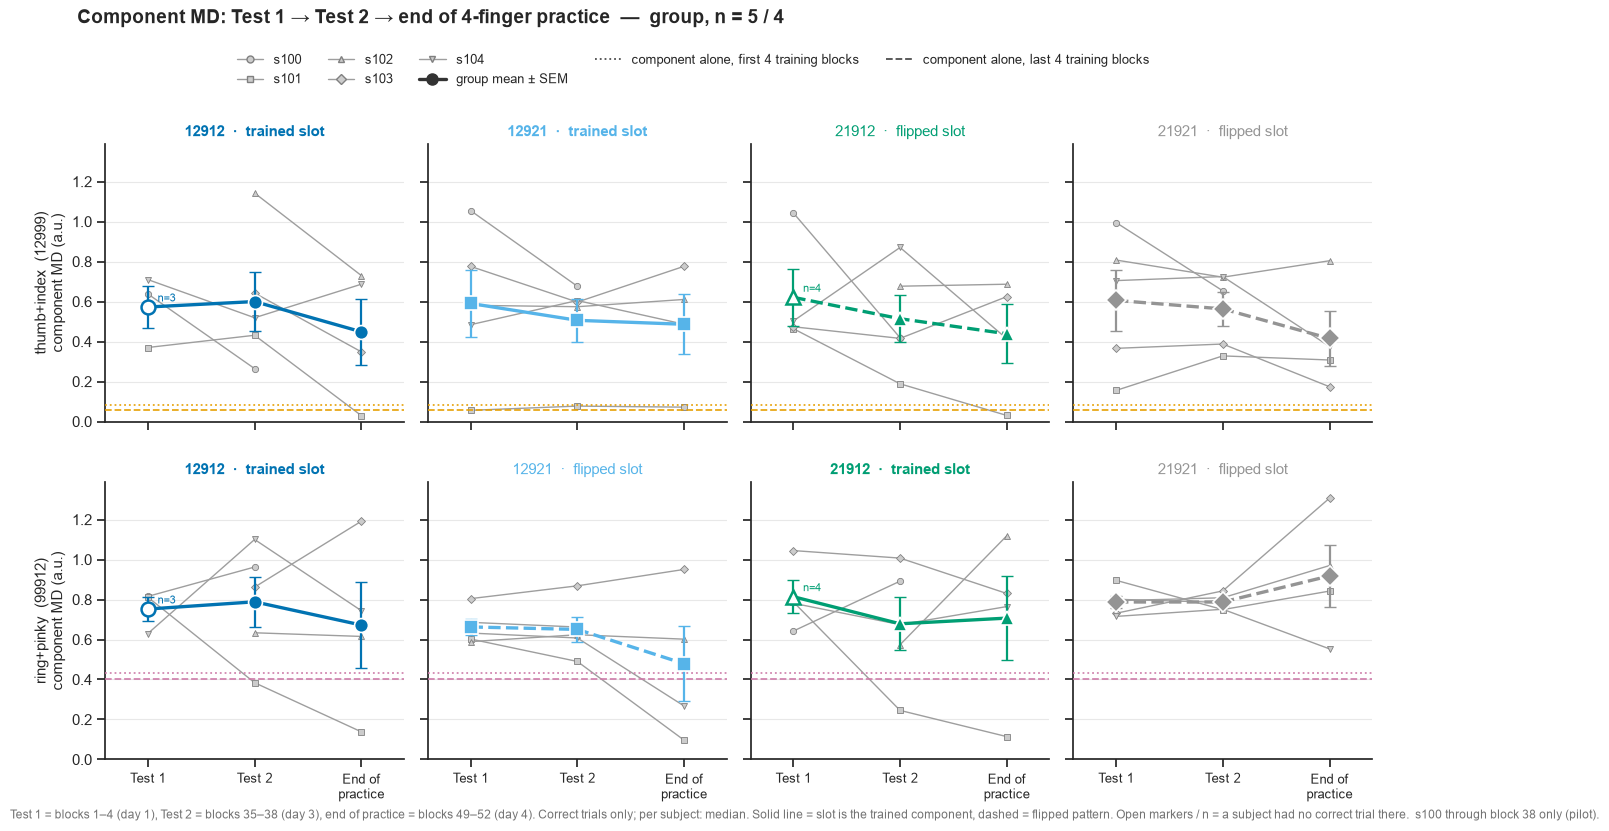

wrote figures/group/component_md/02_tests_by_chord.png


In [5]:
last_4f = [s for s in SEGMENTS if s["kind"] == "4f"][-1]["blocks"]
END_BLOCKS = list(last_4f)[-4:]
PHASES = {"Test 1": list(TEST1_BLOCKS),
          "Test 2": list(TEST2_BLOCKS),
          "End of\npractice": END_BLOCKS}
SUBJ_MARKER = dict(zip(SUBJECTS, ["o", "s", "^", "D", "v", "P", "X"]))
xs = np.arange(len(PHASES))

fig, axes = plt.subplots(len(SLOTS), len(TESTED), figsize=(14, 8.2), sharex=True, sharey=True)
top = 0.0
for r, slot in enumerate(SLOTS):
    comp = roles.component[slot]
    refs = {ls: group(per_subject(blocks, comp, slot), blocks)[0]
            for blocks, ls in [(TRAIN_EARLY, ":"), (TRAIN_LATE, "--")]}
    for k, c in enumerate(TESTED):
        ax = axes[r, k]
        trained = roles.contains(c, slot)
        vals = pd.DataFrame({ph: per_subject(blocks, c, slot) for ph, blocks in PHASES.items()},
                            index=SUBJECTS)
        for sn, row in vals.iterrows():
            ax.plot(xs, row.values, color="0.62", lw=1, marker=SUBJ_MARKER[sn], ms=4.5,
                    mfc="0.8", mec="0.5", mew=.6, zorder=2)
        stats = [group(vals[ph].dropna(), blocks) for ph, blocks in PHASES.items()]
        m, e, n, full = map(np.array, zip(*stats))
        top = np.nanmax([top, np.nanmax(vals.values), np.nanmax(m + e)])
        ax.errorbar(xs, m, yerr=e, color=COLOR[c], lw=2.4, capsize=4, elinewidth=1.6,
                    ls="-" if trained else "--", zorder=4)
        for x, mi, ni, fi in zip(xs, m, n, full):
            if ni:
                ax.plot(x, mi, marker=MARKER[c], ms=10, color=COLOR[c], zorder=5,
                        mfc=COLOR[c] if fi else "white",
                        mec="white" if fi else COLOR[c], mew=1.2 if fi else 1.8)
                if not fi:
                    ax.annotate(f"n={ni}", (x, mi), xytext=(7, 4), textcoords="offset points",
                                fontsize=8, color=COLOR[c])
        for ls, ref in refs.items():
            ax.axhline(ref, color=COLOR[comp], ls=ls, lw=1.3,
                       zorder=3, alpha=.9)
        ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)
        ax.set_xlim(-.4, len(PHASES) - .6)
        ax.set_title(f"{c}  ·  {'trained' if trained else 'flipped'} slot", fontsize=10.5,
                     color=COLOR[c], fontweight="bold" if trained else "normal")
        if k == 0:
            ax.set_ylabel(f"{roles.slot_name(slot)}  ({comp})\ncomponent MD (a.u.)", fontsize=11)
axes[0, 0].set_ylim(0, top * 1.06)

for ax in axes[-1]:
    ax.set_xticks(xs); ax.set_xticklabels(list(PHASES), fontsize=9.5)

handles = [Line2D([], [], color="0.62", lw=1, marker=SUBJ_MARKER[sn], ms=5, mfc="0.8",
                  mec="0.5", label=f"s{sn}") for sn in SUBJECTS]
handles += [Line2D([], [], color="0.2", lw=2.4, marker="o", ms=8, label="group mean ± SEM"),
            Line2D([], [], color="0.3", lw=1.3, ls=":", label="component alone, first 4 training blocks"),
            Line2D([], [], color="0.3", lw=1.3, ls="--", label="component alone, last 4 training blocks")]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False,
           bbox_to_anchor=(.5, .955), fontsize=9.5)
fig.suptitle(f"Component MD: Test 1 → Test 2 → end of 4-finger practice  —  group, n = {N_TXT}",
             fontsize=13.5, fontweight="bold", x=.06, ha="left", y=.995, color="0.15")
fig.text(.012, .008,
         f"Test 1 = blocks {min(TEST1_BLOCKS)}–{max(TEST1_BLOCKS)} (day 1), Test 2 = blocks "
         f"{min(TEST2_BLOCKS)}–{max(TEST2_BLOCKS)} (day 3), end of practice = blocks "
         f"{END_BLOCKS[0]}–{END_BLOCKS[-1]} (day 4). Correct trials only; per subject: median. "
         f"Solid line = slot is the trained component, dashed = flipped pattern. "
         f"Open markers / n = a subject had no correct trial there."
         + (f"  {SHORT_TXT} (pilot)." if SHORT else ""),
         fontsize=8.5, color="0.45", ha="left")
fig.subplots_adjust(left=.08, right=.985, top=.83, bottom=.08, hspace=.22, wspace=.08)
fig.savefig(FIG_DIR / "02_tests_by_chord.png", dpi=200, facecolor="white")
plt.show()
print(f"wrote {(FIG_DIR / '02_tests_by_chord.png').relative_to(ROOT)}")